In [1]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [2]:
!nvidia-smi
!git clone https://github.com/mk-minchul/AdaFace.git
%cd AdaFace
!ls

Fri Oct 23 11:29:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!head -100 README.md

# AdaFace: Quality Adaptive Margin for Face Recognition

Official github repository for AdaFace: Quality Adaptive Margin for Face Recognition. 
The paper (https://arxiv.org/abs/2204.00964) is presented in CVPR 2022 (Oral). 


> Abstract: Recognition in low quality face datasets is challenging because facial attributes are obscured and degraded. Advances in margin-based loss functions have resulted in enhanced discriminability of faces in the embedding space. Further, previous studies have studied the effect of adaptive losses to assign more importance to misclassified (hard) examples. In this work, we introduce another aspect of adaptiveness in the loss function, namely the image quality. We argue that the strategy to emphasize misclassified samples should be adjusted according to their image quality. Specifically, the relative importance of easy and hard samples should be based on the sample's image quality. We propose a new loss function that emphasizes samples of different difficult

In [4]:
!tail -n +100 README.md
!cat requirements.txt


| Arch | Dataset    | Link                                                                                         |
|------|------------|----------------------------------------------------------------------------------------------|
| R18  | CASIA-WebFace     | [gdrive](https://drive.google.com/file/d/1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe/view?usp=sharing) |
| R18  | VGGFace2     | [gdrive](https://drive.google.com/file/d/1k7onoJusC0xjqfjB-hNNaxz9u6eEzFdv/view?usp=sharing) |
| R18  | WebFace4M     | [gdrive](https://drive.google.com/file/d/1J17_QW1Oq00EhSWObISnhWEYr2NNrg2y/view?usp=sharing) |
| R50  | CASIA-WebFace     | [gdrive](https://drive.google.com/file/d/1g1qdg7_HSzkue7_VrW64fnWuHl0YL2C2/view?usp=sharing) |
| R50  | WebFace4M     | [gdrive](https://drive.google.com/file/d/1BmDRrhPsHSbXcWZoYFPJg2KJn1sd3QpN/view?usp=sharing) |
| R50  | MS1MV2     | [gdrive](https://drive.google.com/file/d/1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI/view?usp=sharing) |
| R100 | MS1MV2     | [gdrive](https://dr

In [5]:
!pip install -q gdown
!mkdir -p pretrained
!gdown --fuzzy "https://drive.google.com/file/d/1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe/view?usp=sharing" -O pretrained/adaface_ir18_casia.ckpt
!ls -lh pretrained

Downloading...
From (original): https://drive.google.com/uc?id=1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe
From (redirected): https://drive.google.com/uc?id=1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe&confirm=t&uuid=42e8fbd8-957a-4bf3-beff-1cb897566bf4
To: /content/AdaFace/pretrained/adaface_ir18_casia.ckpt
100% 118M/118M [00:02<00:00, 57.8MB/s]
total 113M
-rw-r--r-- 1 root root 113M Mar 26  2022 adaface_ir18_casia.ckpt


In [6]:
!sed -n 1,60p inference.py

import net
import torch
import os
from face_alignment import align
import numpy as np


adaface_models = {
    'ir_50':"pretrained/adaface_ir50_ms1mv2.ckpt",
}

def load_pretrained_model(architecture='ir_50'):
    # load model and pretrained statedict
    assert architecture in adaface_models.keys()
    model = net.build_model(architecture)
    statedict = torch.load(adaface_models[architecture])['state_dict']
    model_statedict = {key[6:]:val for key, val in statedict.items() if key.startswith('model.')}
    model.load_state_dict(model_statedict)
    model.eval()
    return model

def to_input(pil_rgb_image):
    np_img = np.array(pil_rgb_image)
    brg_img = ((np_img[:,:,::-1] / 255.) - 0.5) / 0.5
    tensor = torch.tensor([brg_img.transpose(2,0,1)]).float()
    return tensor

if __name__ == '__main__':

    model = load_pretrained_model('ir_50')
    feature, norm = model(torch.randn(2,3,112,112))

    test_image_path = 'face_alignment/test_images'
    features = []
    for fname in

In [7]:
!grep -n "ir_18\|ir_50\|def build_model" net.py
!cat requirements.txt

14:def build_model(model_name='ir_50'):
17:    elif model_name == 'ir_50':
23:    elif model_name == 'ir_18':
pytorch-lightning==1.8.6
pytorch<=1.13.1
tqdm
bcolz-zipline
prettytable
menpo
mxnet
opencv-python


In [8]:
!sed -i "s#'ir_50':\"pretrained/adaface_ir50_ms1mv2.ckpt\"#'ir_18':\"pretrained/adaface_ir18_casia.ckpt\"#" inference.py
!sed -i "s#load_pretrained_model('ir_50')#load_pretrained_model('ir_18')#" inference.py
!grep -n "ir_18\|ir_50" inference.py
!python inference.py

9:    'ir_18':"pretrained/adaface_ir18_casia.ckpt",
12:def load_pretrained_model(architecture='ir_50'):
30:    model = load_pretrained_model('ir_18')
/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:287: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if align_type is 'cv2_affine':
/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:290: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif align_type is 'affine':
/content/AdaFace/inference.py:25: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  tensor = torch.tensor([brg_img.transpose(2,0,1)]).float()
tensor([[ 1.0000,  0.6369,  0.0048],
        [ 0.6369,  1.0000, -0.0130],
        [ 0.0048, -0.0130,  1.0000]], grad_fn=<MmBackward0>)


In [9]:
!head -80 README_TRAIN.md


# Data Preparation

## 1. Using InsightFace Dataset


InsightFace provides a variety of labeled face dataset preprocessed to 112x112 size. 

[insightface link](https://github.com/deepinsight/insightface/tree/master/recognition/_datasets_)

The unzipped dataset looks as follows
```
example: faces_webface_112x112
└── train.rec   
├── train.idx                                                                                       │
├── train.lst                                                                                       │
├── agedb_30.bin                                                                                    │
├── calfw.bin                                                                                       │
├── cfp_ff.bin                                                                                      │
├── cfp_fp.bin                                                                                      │
├── cplfw.bin                                            

In [10]:
%cd /content
!mkdir -p data
!gdown --fuzzy https://drive.google.com/file/d/1KxNCrXzln0lal3N4JiYl9cFOIhT78y1l/view?usp=sharing -O data/casia.zip
!ls -lh data

/content
Downloading...
From (original): https://drive.google.com/uc?id=1KxNCrXzln0lal3N4JiYl9cFOIhT78y1l
From (redirected): https://drive.google.com/uc?id=1KxNCrXzln0lal3N4JiYl9cFOIhT78y1l&confirm=t&uuid=e5575963-ff6a-49ea-9518-7a65c1a8e73c
To: /content/data/casia.zip
100% 2.79G/2.79G [00:41<00:00, 67.5MB/s]
total 2.6G
-rw-r--r-- 1 root root 2.6G Aug  4  2021 casia.zip


In [11]:
!python --version

Python 3.13.15


In [12]:
!unzip -q data/casia.zip -d data/
!ls -lh data
!df -h /content | tail -1

total 2.6G
-rw-r--r-- 1 root root 2.6G Aug  4  2021 casia.zip
drwxrwxr-x 2 root root 4.0K May 22  2018 faces_webface_112x112
overlay         113G   49G   65G  43% /


In [13]:
!ls -lh data/faces_webface_112x112

total 3.1G
-rw-rw-r-- 1 root root  73M Dec 14  2017 agedb_30.bin
-rw-rw-r-- 1 root root  71M May 22  2018 calfw.bin
-rw-rw-r-- 1 root root  84M Dec 14  2017 cfp_ff.bin
-rw-rw-r-- 1 root root  73M Dec 14  2017 cfp_fp.bin
-rw-rw-r-- 1 root root  60M May 22  2018 cplfw.bin
-rw-rw-r-- 1 root root  62M Dec 14  2017 lfw.bin
-rw-rw-r-- 1 root root   14 Dec 14  2017 property
-rw-rw-r-- 1 root root 8.4M Dec 14  2017 train.idx
-rw-rw-r-- 1 root root  70M Dec 14  2017 train.lst
-rw-rw-r-- 1 root root 2.6G Dec 14  2017 train.rec


In [14]:
!cat data/faces_webface_112x112/property

import pickle
with open('data/faces_webface_112x112/lfw.bin', 'rb') as f:
    bins, issame = pickle.load(f, encoding='bytes')
print(len(bins), len(issame))
print(type(bins[0]))
print(issame[:10])

10572,112,112
12000 6000
<class 'bytes'>
[True, True, True, True, True, True, True, True, True, True]


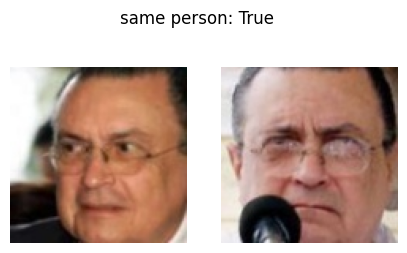

In [15]:
import io
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(5, 3))
for ax, i in zip(axes, [0, 1]):
    ax.imshow(Image.open(io.BytesIO(bins[i])))
    ax.axis('off')
plt.suptitle(f"same person: {issame[0]}")
plt.show()

In [17]:
%cd /content/AdaFace

/content/AdaFace


In [19]:
import torch
import cv2
import numpy as np
from inference import load_pretrained_model

# 1. Load pretrained AdaFace model
model = load_pretrained_model('ir_18').cuda()
model.eval()

# 2. Preprocess images
def preprocess_image(image_bytes):
    image = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise ValueError("Could not decode image")

    # OpenCV already uses BGR (correct for AdaFace)
    image = cv2.resize(image, (112, 112))

    # Normalise pixels to [-1, 1]
    image = image.astype(np.float32) / 127.5 - 1.0

    # Convert to tensor (3, 112, 112)
    return torch.from_numpy(image).permute(2, 0, 1)

# 3. Extract embeddings in batches
def get_embeddings(model, images, batch_size=128):
    results = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = torch.stack([
                preprocess_image(img)
                for img in images[i:i + batch_size]
            ]).cuda()

            features, _ = model(batch)
            results.append(features.cpu())

    return torch.cat(results, dim=0)

# 4. Extract LFW embeddings
embeddings = get_embeddings(model, bins)

# 5. Check shape
print("Embedding shape:", embeddings.shape)

assert embeddings.shape == (12000, 512), "Unexpected embedding shape!"

print("Piece 1 completed successfully!")

Embedding shape: torch.Size([12000, 512])
Piece 1 completed successfully!
